# Validate ERA5-Land time series

Check the daily values derived from the experimental ERA5-Land time-series product against the standard `reanalysis-era5-land` dataset for one cell and one wet month. Run `21_compute_climate_summaries.ipynb` first.

- **Day boundary:** the standard dataset accumulates precipitation from 00 UTC, so its 00:00 value on D+1 is the full total for day D. It should match the time-series daily total, which sums the period-ending hours D 01:00 through D+1 00:00.
- **Spot-check:** the monthly precipitation total and mean temperature should match.

Results are saved to `outputs/climate/validation_checks.csv` and `validation_daily.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cds_pull import ClimateConfig
from cds_pull.validation import (
    compare_daily,
    fetch_standard,
    read_standard,
    standard_daily,
    validation_checks,
)

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"

## Validation settings

In [2]:
config = ClimateConfig.from_yaml(ROOT / "configs" / "climate.yaml", project_root=ROOT)
VALIDATION_SITE = "WadiGaza"
VALIDATION_YEAR, VALIDATION_MONTH = 2020, 1  # a wet month in the study period

site_cells = pd.read_csv(config.output_dir / "site_cells.csv").set_index("site")
cell = site_cells.loc[VALIDATION_SITE]
daily = pd.read_csv(config.output_dir / "daily_climate.csv")
cell_daily = daily.loc[daily["cell_id"] == cell["cell_id"]]
print(f"{VALIDATION_SITE}: cell {cell['cell_id']}, {VALIDATION_YEAR}-{VALIDATION_MONTH:02d}")

WadiGaza: cell N31.5_E34.4, 2020-01


## Standard dataset download

In [3]:
path = fetch_standard(
    config, cell["cell_id"], cell["cell_lat"], cell["cell_lon"], VALIDATION_YEAR, VALIDATION_MONTH
)
standard = read_standard(path)
print(f"{len(standard)} hourly rows from {path.relative_to(ROOT)}")

1440 hourly rows from outputs/climate/raw/validation/N31.5_E34.4_2020-01.nc


## Daily comparison

In [4]:
comparison = compare_daily(cell_daily, standard_daily(standard), VALIDATION_YEAR, VALIDATION_MONTH)
comparison.insert(0, "cell_id", cell["cell_id"])
comparison.to_csv(config.output_dir / "validation_daily.csv", index=False)
comparison.round(4)

,cell_id,date,precip_mm,t2m_mean_24h_c,t2m_midrange_c,std_precip_mm,std_t2m_mean_24h_c,std_t2m_midrange_c,precip_diff_mm,t2m_mean_24h_diff_c,t2m_midrange_diff_c
0,N31.5_E34.4,2020-01-01,0.0949,13.0911,13.1395,0.094900,13.091000,13.139400,0.0000,0.0001,0.0001
1,N31.5_E34.4,2020-01-02,0.3054,13.5497,13.6736,0.305400,13.549600,13.673500,0.0000,0.0001,0.0001
2,N31.5_E34.4,2020-01-03,0.3226,13.0945,13.2472,0.322600,13.094400,13.247100,-0.0000,0.0001,0.0001
3,N31.5_E34.4,2020-01-04,6.1138,12.3933,12.6767,6.113800,12.393200,12.676500,0.0000,0.0001,0.0002
4,N31.5_E34.4,2020-01-05,1.2068,13.1307,13.7784,1.206700,13.130600,13.778400,0.0001,0.0001,0.0000
5,N31.5_E34.4,2020-01-06,0.0009,12.9170,13.4222,0.000900,12.916900,13.422200,0.0000,0.0001,0.0001
6,N31.5_E34.4,2020-01-07,0.2040,13.5593,13.8234,0.204000,13.559300,13.823300,0.0000,0.0000,0.0001
7,N31.5_E34.4,2020-01-08,16.1543,12.3350,12.5236,16.154301,12.334900,12.523500,-0.0000,0.0001,0.0001
8,N31.5_E34.4,2020-01-09,9.2011,12.1236,12.5641,9.201100,12.123500,12.564000,-0.0000,0.0001,0.0001
9,N31.5_E34.4,2020-01-10,3.5507,11.1972,11.4335,3.550700,11.197100,11.433400,0.0000,0.0001,0.0001


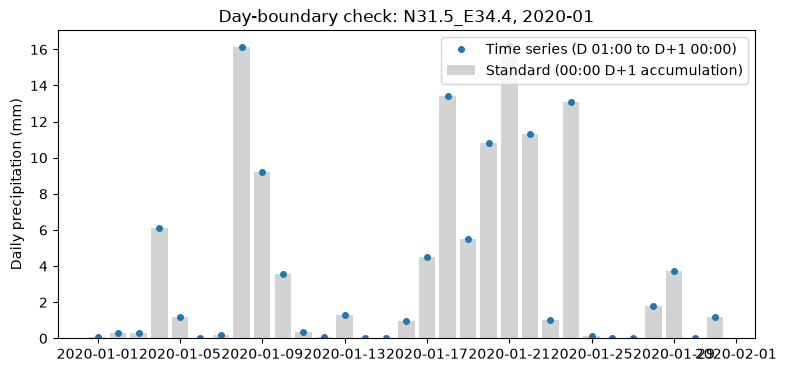

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
dates = pd.to_datetime(comparison["date"])
ax.bar(dates, comparison["std_precip_mm"], color="lightgrey", label="Standard (00:00 D+1 accumulation)")
ax.plot(dates, comparison["precip_mm"], "o", color="tab:blue", markersize=4, label="Time series (D 01:00 to D+1 00:00)")
ax.set_ylabel("Daily precipitation (mm)")
ax.set_title(f"Day-boundary check: {cell['cell_id']}, {VALIDATION_YEAR}-{VALIDATION_MONTH:02d}")
ax.legend()
plt.show()

## Checks

Tolerances: 0.01 mm per day for precipitation and 0.01 °C for the monthly mean temperature.

In [6]:
checks = validation_checks(comparison, cell["cell_id"])
checks.to_csv(config.output_dir / "validation_checks.csv", index=False)
display(checks)
if not checks["passed"].all():
    raise RuntimeError("Validation against the standard ERA5-Land dataset failed; inspect the tables above.")

,check,scope,passed,detail
0,validation_day_boundary,N31.5_E34.4 2020-01,True,17 rainy days; max |diff| 0.00006 mm
1,validation_monthly_precip,N31.5_E34.4 2020-01,True,time series 122.63 mm; standard 122.63 mm
2,validation_monthly_t2m,N31.5_E34.4 2020-01,True,time series 12.910 C; standard 12.910 C
